# Para quem ligar primeiro? Previsão de conversão de leads

**Pergunta de negócio.** Uma equipe de televendas recebe mais leads do que consegue contatar.
Dá para ordenar a fila de modo que as ligações feitas rendam mais conversões?

**Dados.** 41.188 contatos de telemarketing de um banco português, de maio/2008 a novembro/2010
([UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), CC BY 4.0).
O alvo é se o cliente contratou o produto oferecido.

**O que este notebook mostra, em ordem:**

1. Os dados mudam de regime no meio do caminho, e isso decide como o modelo deve ser avaliado.
2. Uma variável do dataset entrega a resposta (vazamento) e precisa sair.
3. A validação "padrão" (aleatória) promete muito mais do que o modelo entrega quando é usado
   como seria na vida real: treinado no passado, pontuando o futuro.
4. Um modelo simples empata com um complexo, e ambos superam uma regra de bolso.
5. O que isso vale em conversões, com a capacidade da equipe limitada.
6. Onde o modelo falha: o nível das probabilidades quando o regime muda.

Todo o código de modelagem está no pacote `lead_scoring` (pasta `src/`), com testes. O notebook
só chama as funções e discute os resultados.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from lead_scoring import analise, graficos
from lead_scoring.dados import ALVO, ARQUIVO_PADRAO, baixar, carregar

# Avisos esperados: `pdays` todo ausente nos primeiros meses (ninguém tinha contato anterior)
# e meses do ano que aparecem no teste sem estar na janela de treino.
warnings.filterwarnings("ignore", message="Skipping features without any observed values")
warnings.filterwarnings("ignore", message="Found unknown categories")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")


def mostrar(figura):
    display(figura)
    plt.close(figura)


baixar()
bruto = pd.read_csv(ARQUIVO_PADRAO, sep=";")
df = carregar()
print(f"{len(df):,} leads | conversão geral: {df[ALVO].mean():.1%} | {df['periodo'].min()} a {df['periodo'].max()}")

41,188 leads | conversão geral: 11.3% | 2008-05 a 2010-11


## 1. Os dados mudam de regime

O arquivo não traz o ano, mas as linhas estão em ordem cronológica. A função
`reconstruir_periodo` recupera o ano-mês de cada contato (sempre que o mês "volta", virou o ano).
Com a linha do tempo em mãos, aparece o fato mais importante do dataset:

In [2]:
por_trimestre = (
    df.assign(trimestre=df["periodo"].dt.asfreq("Q"))
    .groupby("trimestre")[ALVO]
    .agg(leads="size", conversoes="sum", taxa="mean")
)
por_trimestre

,leads,conversoes,taxa
trimestre,,,
2008Q2,12137,428,0.035
2008Q3,11860,678,0.057
2008Q4,3693,233,0.063
2009Q1,282,126,0.447
2009Q2,8967,1230,0.137
2009Q3,1215,436,0.359
2009Q4,976,436,0.447
2010Q1,264,150,0.568
2010Q2,615,326,0.530


Em 2008 a operação faz ligações em massa e converte entre 3% e 6%. A partir de meados de 2009 o
volume cai a uma fração e a conversão passa de 35%: a equipe passou a ligar para listas muito
menores e mais selecionadas. **São dois problemas diferentes dentro do mesmo arquivo.**

Consequência prática: se eu embaralhar as linhas para validar o modelo, ele vai aprender a
distinguir os dois regimes (o que é fácil) e parecer muito melhor do que é na tarefa que importa,
que é ordenar os leads de *um mesmo* período.

## 2. Vazamento: a variável que só existe depois da ligação

`duration` é a duração da chamada. Quem contrata fica mais tempo na linha, então a variável é
ótima para "prever" o resultado. Só que ela não existe no momento de decidir para quem ligar.

In [3]:
vazamento = analise.demonstrar_vazamento(bruto)
pd.Series(vazamento, name="AUC em validação aleatória").to_frame()

,AUC em validação aleatória
com duration,0.878
sem duration,0.692


A mesma regressão logística salta de 0,69 para 0,88 de AUC só por incluir `duration`. Esse ganho
é falso: em produção a variável não estaria disponível. Ela é removida já na carga dos dados
(`lead_scoring.dados.COLUNAS_VAZAMENTO`) e não entra em nenhum modelo daqui em diante.

## 3. Validação aleatória x validação no tempo

Dois modelos, cada um avaliado de dois jeitos:

- **Validação aleatória:** 5 dobras estratificadas com embaralhamento. É o padrão dos tutoriais.
- **Validação no tempo (walk-forward):** cinco blocos de teste consecutivos. Cada bloco é pontuado
  por um modelo treinado apenas com os 12 meses anteriores a ele. É assim que o modelo seria usado.

A AUC no tempo é a **média das AUCs de cada bloco**, não a AUC de todos os blocos juntos. Juntar
blocos com taxas de conversão diferentes daria crédito ao modelo por acertar o período, não o lead
(o teste `test_auc_media_por_bloco_nao_premia_acertar_o_periodo` demonstra o efeito).

,AUC validação aleatória,AUC no tempo (média dos blocos),pior bloco,melhor bloco
modelo,,,,
"LightGBM, todas as variáveis",0.804,0.634,0.569,0.732
"Logística, 6 variáveis",0.692,0.659,0.593,0.764


Teto: AUC do modelo completo em validação aleatória só dentro do regime recente = 0.704


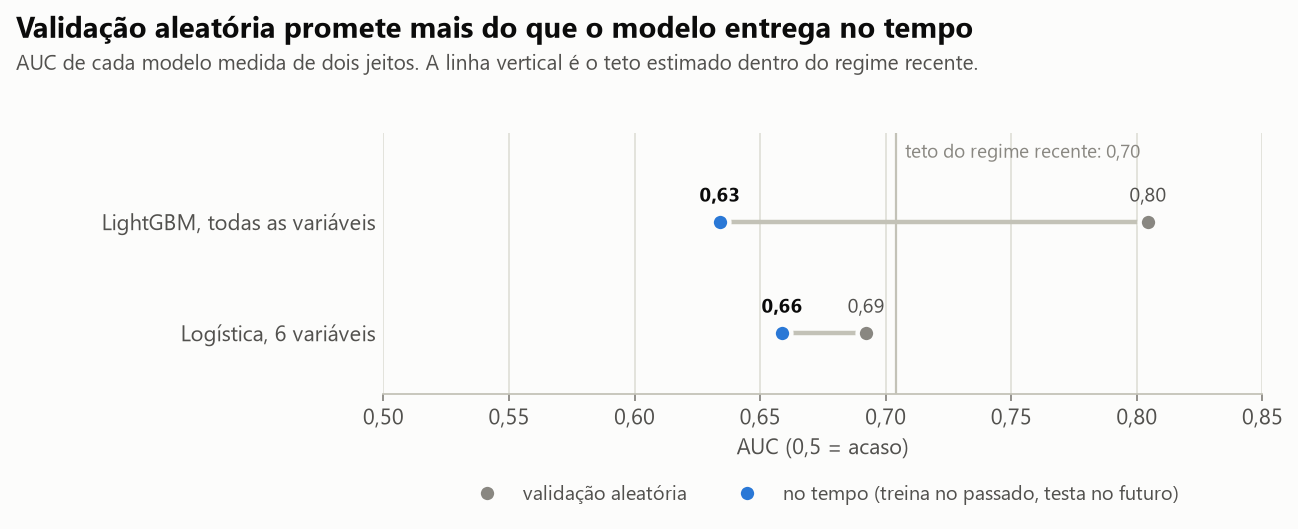

In [4]:
promessa = analise.aleatoria_x_temporal(df)
teto = analise.teto_do_regime_novo(df)
display(promessa)
print(f"Teto: AUC do modelo completo em validação aleatória só dentro do regime recente = {teto:.3f}")
mostrar(graficos.promessa_x_realidade(promessa, teto))

O LightGBM com todas as variáveis cai de 0,80 para 0,63. De onde vinha a diferença? Dos
indicadores macroeconômicos, que funcionam como um carimbo de data:

In [5]:
analise.macro_dentro_do_mes(df)

,mediana de valores distintos por mês,máximo
emp_var_rate,1.000,1
cons_price_idx,1.000,1
cons_conf_idx,1.000,1
euribor3m,14.000,22
nr_employed,1.000,1


Quatro dos cinco indicadores têm **um único valor por mês**. Para o modelo, eles dizem "este
contato é de tal mês", e o mês diz em que regime de conversão o contato está. Em validação
aleatória isso vale ouro; no tempo, o mês seguinte traz valores que o modelo nunca viu.

O teto de 0,70 é a referência honesta: mesmo com tudo a favor (validação aleatória, todas as
variáveis), dentro do regime recente as variáveis disponíveis explicam só isso sobre *quem*
converte. A meta realista para um modelo usado no tempo é chegar perto de 0,70, não de 0,80.

## 4. Três concorrentes, bloco a bloco

Além dos dois modelos, entra uma **regra de bolso** que um gestor montaria só com filtros de CRM:
primeiro quem já comprou em campanha anterior, depois quem já foi contatado, depois o resto, com
celular na frente de telefone fixo. Se o modelo não superar isso, não vale a complexidade.

,"LightGBM, todas as variáveis","Logística, 6 variáveis",Regra de bolso (sem modelo)
bloco,,,
2009-04 a 2009-05,0.569,0.606,0.496
2009-06 a 2009-08,0.575,0.593,0.562
2009-09 a 2009-12,0.619,0.628,0.624
2010-03 a 2010-06,0.676,0.703,0.636
2010-07 a 2010-11,0.732,0.764,0.683


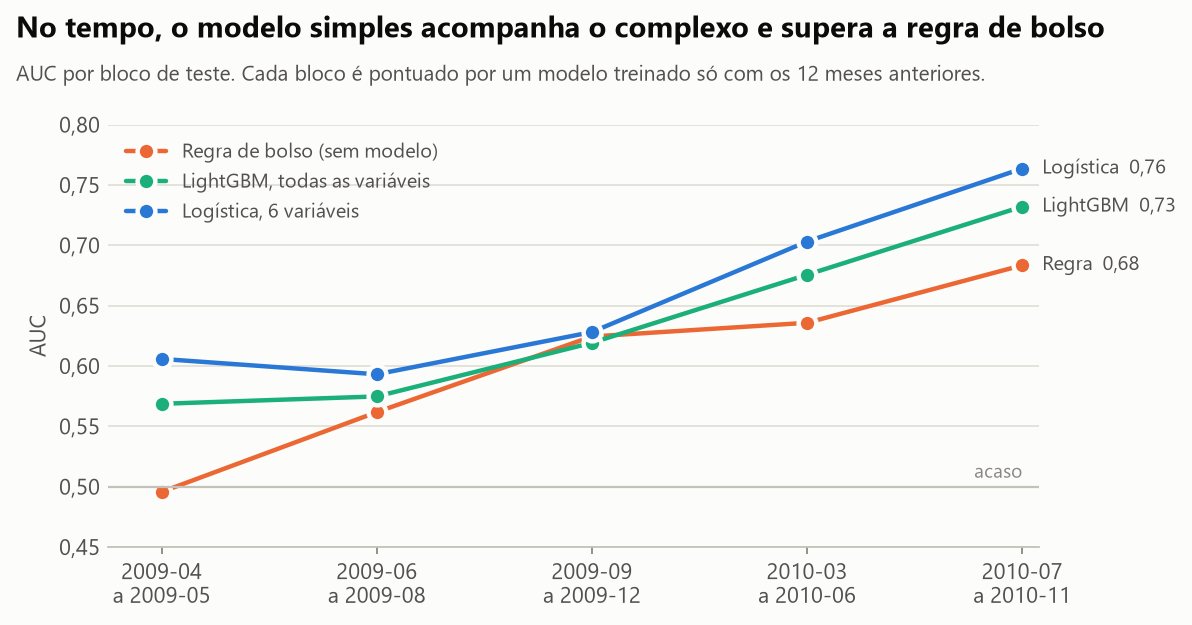

In [6]:
juntas, por_bloco = analise.previsoes_no_tempo(df)
display(pd.DataFrame({nome: tabela["auc"] for nome, tabela in por_bloco.items()}))
mostrar(graficos.auc_por_bloco(por_bloco))

Todos melhoram com o tempo, porque a janela de treino vai se enchendo de exemplos do regime novo.
No primeiro bloco a regra de bolso não ordena nada (AUC 0,50): quase ninguém tinha histórico de
contato ainda.

### Com incerteza

Os blocos têm entre 900 e 8.000 leads, então as AUCs têm ruído. O bootstrap abaixo reamostra os
leads dentro de cada bloco (1.000 repetições) e usa a mesma reamostra para os três concorrentes,
o que permite dar o intervalo da **diferença** entre eles.

In [7]:
resumo, diferencas = analise.comparar_concorrentes(juntas)
display(resumo)
display(diferencas)

,AUC no tempo,IC 95% inferior,IC 95% superior
"Logística, 6 variáveis",0.659,0.646,0.672
"LightGBM, todas as variáveis",0.634,0.622,0.648
Regra de bolso (sem modelo),0.600,0.588,0.613


,diferença de AUC,IC 95% inferior,IC 95% superior
"Logística, 6 variáveis − LightGBM, todas as variáveis",0.025,0.013,0.035
"Logística, 6 variáveis − Regra de bolso (sem modelo)",0.059,0.045,0.072


A logística com 6 variáveis supera a regra de bolso com folga (o intervalo da diferença fica
longe de zero). Contra o LightGBM a diferença é pequena, e aqui cabe uma ressalva de método:

**A configuração escolhida saiu de uma grade de 24 combinações avaliadas nestes mesmos blocos.**
Quem escolhe o melhor de 24 no mesmo conjunto em que reporta o resultado superestima a vantagem
do escolhido. A grade completa está abaixo, por transparência.

In [8]:
grade = analise.grade_de_configuracoes(df)
grade.head(12)

,variáveis,modelo,janela de treino,AUC no tempo,pior bloco
0,enxuto (6 variáveis),logistica,12 meses,0.659,0.593
1,enxuto (6 variáveis),logistica,6 meses,0.654,0.582
2,perfil + contato,logistica,12 meses,0.649,0.581
3,enxuto (6 variáveis),logistica,todo o passado,0.646,0.596
4,tudo (inclui macro),lightgbm,todo o passado,0.644,0.569
5,perfil + contato + calendário,logistica,6 meses,0.644,0.577
6,enxuto (6 variáveis),lightgbm,6 meses,0.643,0.584
7,perfil + contato,logistica,6 meses,0.643,0.576
8,perfil + contato,logistica,todo o passado,0.638,0.586
9,enxuto (6 variáveis),lightgbm,12 meses,0.635,0.576


As dez primeiras colocadas cabem numa faixa de 0,025 de AUC, da mesma ordem do intervalo de
confiança de cada uma (cerca de ±0,013). A leitura segura não é "o modelo simples é melhor", e sim **"o modelo complexo não é melhor"**.
Com desempenho equivalente, fico com a logística de 6 variáveis: é mais fácil de explicar, de
auditar e de manter.

## 5. O que isso vale: conversões com capacidade limitada

AUC não paga conta. A pergunta do gestor é: *com as ligações que minha equipe consegue fazer,
quantas conversões a mais eu tenho?* A tabela simula a equipe contatando só uma fração dos leads
de cada bloco, escolhidos de três formas. "Sem priorizar" é o valor esperado de ligar em ordem
aleatória. Empates no score são resolvidos por valor esperado, para não favorecer quem aparece
primeiro no arquivo.

,ligações,sem priorizar,regra de bolso,modelo,modelo vs sem priorizar,modelo vs regra
capacidade,,,,,,
0.100,1321,317.343,476.430,561.500,0.769,0.179
0.200,2644,635.480,850.052,1011.981,0.592,0.190
0.300,3966,952.941,1161.892,1360.818,0.428,0.171
0.500,6610,1588.421,1731.323,1954.381,0.230,0.129


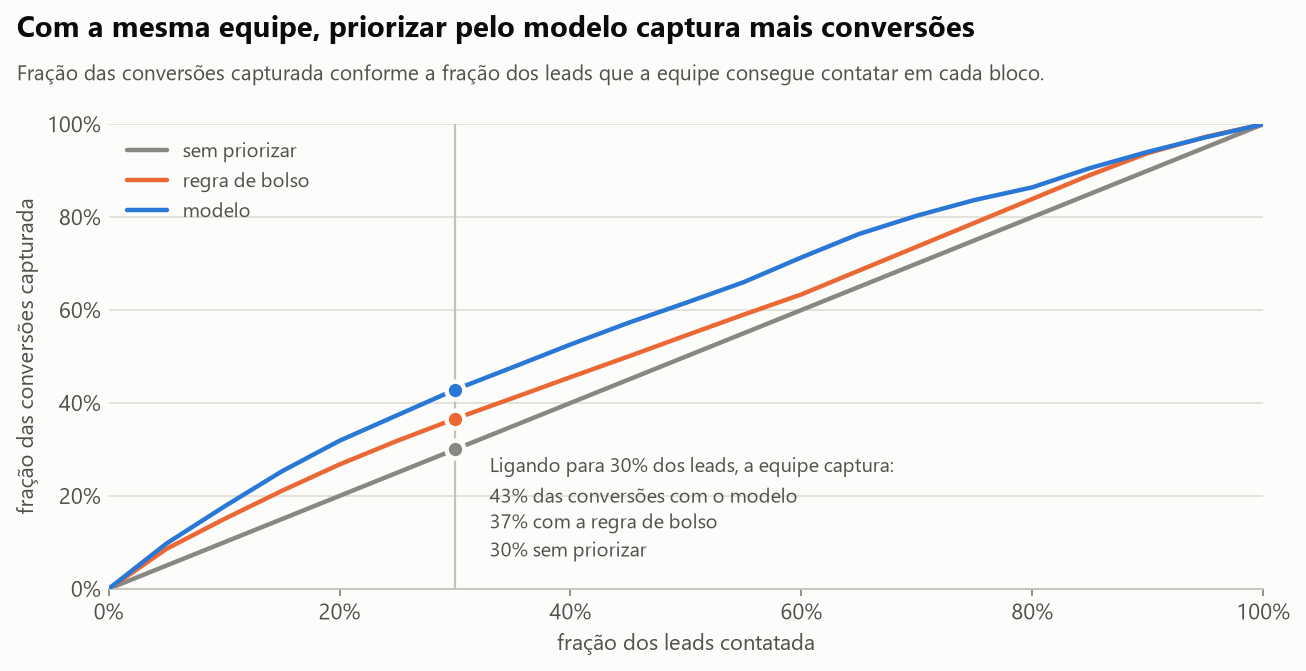

In [9]:
capacidade = analise.ganho_com_capacidade(juntas)
display(capacidade.round(3))
mostrar(graficos.curva_de_ganho(analise.curva_de_ganho(juntas)))

Com capacidade para contatar 30% dos leads, o modelo entrega cerca de 43% mais conversões que a
ordem aleatória e 17% mais que a regra de bolso, **com o mesmo número de ligações**. O ganho é
maior quanto mais apertada a capacidade e desaparece quando a equipe consegue ligar para todos.

É um ganho moderado, coerente com uma AUC de 0,66. Vale a pena porque o custo de ordenar a fila
é praticamente zero, não porque o modelo seja excelente.

## 6. Onde o modelo falha: o nível das probabilidades

Ordenar é uma coisa; acertar o *nível* da probabilidade é outra. O nível importa quando a
probabilidade vira previsão ("esta lista deve render quantas vendas?"). Abaixo, o total de
conversões previsto em cada bloco contra o real, de dois jeitos:

- **modelo cru:** soma das probabilidades que saem do modelo;
- **nível corrigido:** as probabilidades são deslocadas para a taxa de conversão dos 2.000 leads
  mais recentes anteriores ao bloco (correção clássica de mudança de taxa-base, no logit). Usa só
  informação que existiria no momento de pontuar e não muda a ordem dos leads.

,leads,taxa no treino,taxa recente,taxa real,conversões reais,previstas (cru),previstas (corrigido),erro (cru),erro (corrigido),Brier (cru),Brier (corrigido)
bloco,,,,,,,,,,,
2009-04 a 2009-05,8252,0.052,0.112,0.117,966,506.481,1058.500,-0.476,0.096,0.105,0.101
2009-06 a 2009-08,1663,0.077,0.116,0.357,594,196.411,278.589,-0.669,-0.531,0.279,0.259
2009-09 a 2009-12,1243,0.138,0.331,0.436,542,258.146,508.027,-0.524,-0.063,0.278,0.229
2010-03 a 2010-06,879,0.195,0.400,0.542,476,275.269,443.886,-0.422,-0.067,0.274,0.223
2010-07 a 2010-11,1179,0.439,0.486,0.506,597,548.283,597.652,-0.082,0.001,0.209,0.207


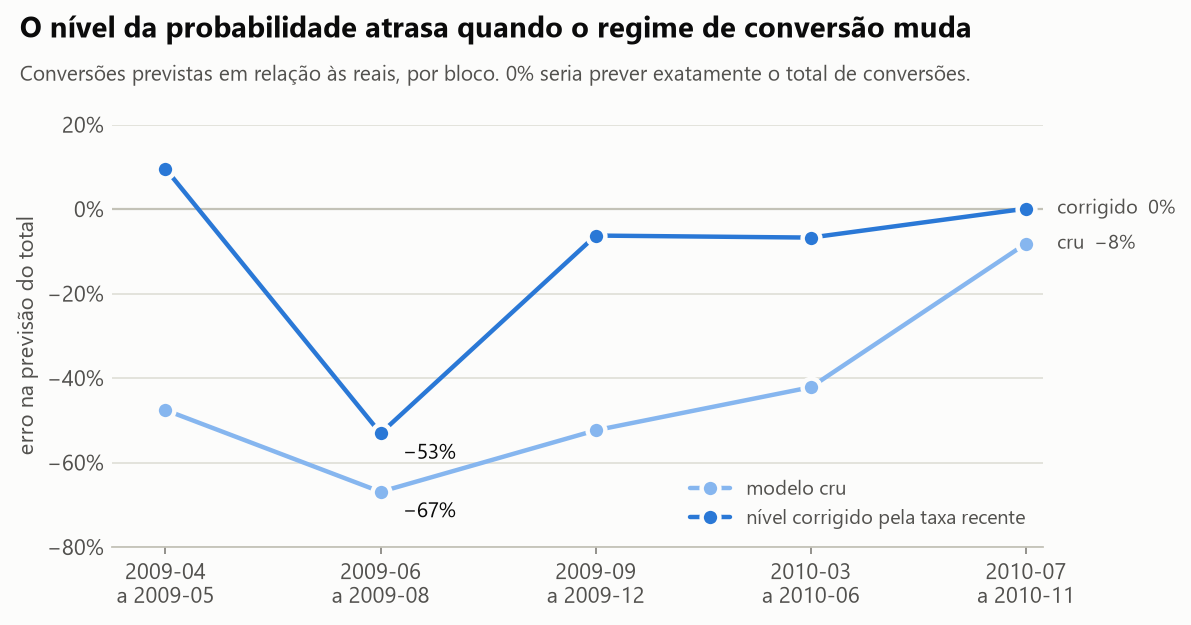

In [10]:
calibracao = analise.calibracao_no_tempo(juntas, por_bloco[analise.ESCOLHIDO])
display(calibracao.round(3))
mostrar(graficos.calibracao(calibracao))

O modelo cru subestima as conversões em todos os blocos, por até 67%: ele foi treinado em meses
de conversão baixa e pontua meses de conversão alta. A correção de nível resolve quatro dos cinco
blocos (erro de até 10%), mas **não o bloco logo após a virada de regime** (junho a agosto de
2009, erro de 53%): nenhuma informação anterior indicava que a conversão ia triplicar.

Conclusão operacional: o score serve para **ordenar** a fila desde o primeiro dia. Para **prever
volume de vendas**, a probabilidade só é confiável com o nível corrigido e monitorado, e mesmo
assim falha na primeira janela após uma mudança de regime. Previsto x realizado por período é o
alarme que precisa existir em produção.

Tentei antes uma recalibração de Platt ajustada no bloco anterior. Ela melhorou três blocos e
piorou o último, porque o mapa de calibração de um modelo foi aplicado ao modelo retreinado do
bloco seguinte. A correção de nível é mais simples e não tem esse problema.

## 7. O que o modelo aprendeu

Coeficientes da logística treinada nos 12 meses mais recentes. As variáveis numéricas estão
padronizadas (o coeficiente é o efeito de um desvio-padrão). `contact_telephone` compara telefone
fixo com celular.

In [11]:
analise.coeficientes_do_escolhido(df)

,coeficiente,razão de chances
contatado_antes,0.566,1.762
poutcome_success,0.419,1.520
poutcome_nonexistent,0.167,1.181
age,0.124,1.132
previous,-0.152,0.859
campaign,-0.178,0.837
poutcome_failure,-0.409,0.664
contact_telephone,-1.133,0.322


A leitura bate com a intuição de quem opera mídia e CRM: quem já teve contato anterior e quem
já comprou converte mais; pelo telefone fixo a chance é cerca de um terço da do celular; insistir
(muitas tentativas na mesma campanha) reduz a chance. Os coeficientes de `previous` e `poutcome_*` são
correlacionados entre si, então não devem ser lidos isoladamente como efeito causal.

## Conclusões

1. **A forma de validar muda a resposta.** O mesmo modelo vale AUC 0,80 em validação aleatória e
   0,63 quando avaliado como seria usado. Quem reporta o primeiro número promete o que não entrega.
2. **Simples basta.** Uma logística com 6 variáveis empata com LightGBM com 20 e supera uma regra
   de bolso por 0,06 de AUC (IC 95% de 0,045 a 0,072).
3. **O ganho é moderado e real.** Com capacidade para 30% dos leads, cerca de 43% mais conversões
   que a ordem aleatória e 17% mais que a regra de bolso.
4. **Probabilidade não é previsão sem monitoramento.** O nível das probabilidades atrasa quando o
   regime muda; a correção pela taxa recente ajuda, mas não antecipa a virada.

## Limitações

- **Dados de um único banco, de 2008 a 2010**, em plena crise financeira. Os números não se
  transferem para outra operação; o método sim.
- **Seleção.** A partir de 2009 o banco já escolhia para quem ligar (por isso a conversão alta).
  O modelo aprende sobre leads que alguém já filtrou, e não sabemos como.
- **Escolha na mesma amostra.** A configuração final saiu de 24 testadas nos mesmos blocos de
  avaliação. A comparação com a regra de bolso é robusta a isso; a comparação com o LightGBM não.
- **Sem dados de custo e receita.** O ganho está em conversões, não em reais. Com margem por
  venda e custo por ligação, o passo seguinte seria uma curva de lucro.
- **Previsão não é causa.** O score diz quem tende a converter, não quem converte *por causa* da
  ligação. Priorizar quem compraria de qualquer jeito não gera venda incremental. Responder isso
  exige experimento ou modelo de uplift.